In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load and Inspect the Raw Financial Datasets

The Income Statement and Cash Flow datasets contain annual financial information for companies in the investment universe. Before filtering or transforming the data, we first inspect their size, structure, columns, and data quality.

This initial inspection helps us understand the raw datasets and identify potential issues before performing data cleaning.

In [ ]:
df_income = pd.read_csv("/content/drive/MyDrive/Data Handling and Machine Learning/week_03/raw/income_statement.csv",sep=";")

df_cashflow = pd.read_csv("/content/drive/MyDrive/Data Handling and Machine Learning/week_03/raw/cash_flow.csv",sep=";")

## Dataset Overview

Before cleaning the datasets, the available columns and structure of the raw Income Statement and Cash Flow data are inspected.

In [ ]:
print("Income Statement Columns:")
print(df_income.columns.tolist())

print("\nCash Flow Columns:")
print(df_cashflow.columns.tolist())

Income Statement Columns:
['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Publish Date', 'Restated Date', 'Shares (Basic)', 'Shares (Diluted)', 'Revenue', 'Cost of Revenue', 'Gross Profit', 'Operating Expenses', 'Selling, General & Administrative', 'Research & Development', 'Depreciation & Amortization', 'Operating Income (Loss)', 'Non-Operating Income (Loss)', 'Interest Expense, Net', 'Pretax Income (Loss), Adj.', 'Abnormal Gains (Losses)', 'Pretax Income (Loss)', 'Income Tax (Expense) Benefit, Net', 'Income (Loss) from Continuing Operations', 'Net Extraordinary Gains (Losses)', 'Net Income', 'Net Income (Common)']

Cash Flow Columns:
['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Publish Date', 'Restated Date', 'Shares (Basic)', 'Shares (Diluted)', 'Net Income/Starting Line', 'Depreciation & Amortization', 'Non-Cash Items', 'Change in Working Capital', 'Change in Accounts Receivable', 'Change in Inventories', 'Cha

### Preview of the Raw Data

A sample of the raw datasets is displayed to understand the format and structure of the financial records before cleaning.

In [ ]:
print("Income Statement:")
display(df_income.head())

print("\nCash Flow:")
display(df_cashflow.head())

Income Statement:


,Ticker,SimFinId,Currency,Fiscal Year,Fiscal Period,Report Date,Publish Date,Restated Date,Shares (Basic),Shares (Diluted),...,Non-Operating Income (Loss),"Interest Expense, Net","Pretax Income (Loss), Adj.",Abnormal Gains (Losses),Pretax Income (Loss),"Income Tax (Expense) Benefit, Net",Income (Loss) from Continuing Operations,Net Extraordinary Gains (Losses),Net Income,Net Income (Common)
0,A,45846,USD,2020,FY,2020-10-31,2020-12-18,2022-12-21,309000000.0,312000000.0,...,-4000000.0,-70000000.0,8.420000e+08,NaN,8.420000e+08,-123000000.0,719000000,NaN,719000000,719000000
1,A,45846,USD,2021,FY,2021-10-31,2021-12-17,2023-12-20,305000000.0,307000000.0,...,13000000.0,-79000000.0,1.360000e+09,NaN,1.360000e+09,-150000000.0,1210000000,NaN,1210000000,1210000000
2,A,45846,USD,2022,FY,2022-10-31,2022-12-21,2024-12-20,304000000.0,307000000.0,...,-114000000.0,-75000000.0,1.504000e+09,NaN,1.504000e+09,-250000000.0,1254000000,NaN,1254000000,1254000000
3,A,45846,USD,2023,FY,2023-10-31,2023-12-20,2025-12-22,294000000.0,296000000.0,...,-11000000.0,-44000000.0,1.339000e+09,NaN,1.339000e+09,-99000000.0,1240000000,NaN,1240000000,1240000000
4,A,45846,USD,2024,FY,2024-10-31,2024-12-20,2025-12-22,290000000.0,291000000.0,...,33000000.0,-16000000.0,1.521000e+09,NaN,1.521000e+09,-232000000.0,1289000000,NaN,1289000000,1289000000



Cash Flow:


,Ticker,SimFinId,Currency,Fiscal Year,Fiscal Period,Report Date,Publish Date,Restated Date,Shares (Basic),Shares (Diluted),...,Net Cash from Operating Activities,Change in Fixed Assets & Intangibles,Net Change in Long Term Investment,Net Cash from Acquisitions & Divestitures,Net Cash from Investing Activities,Dividends Paid,Cash from (Repayment of) Debt,Cash from (Repurchase of) Equity,Net Cash from Financing Activities,Net Change in Cash
0,A,45846,USD,2020,FY,2020-10-31,2020-12-18,2022-12-21,309000000.0,312000000.0,...,9.210000e+08,-118000000.0,NaN,NaN,-1.470000e+08,-222000000.0,-45000000.0,-4.090000e+08,-7.170000e+08,59000000
1,A,45846,USD,2021,FY,2021-10-31,2021-12-17,2023-12-20,305000000.0,307000000.0,...,1.485000e+09,-187000000.0,12000000.0,-547000000.0,-7.490000e+08,-236000000.0,356000000.0,-7.330000e+08,-6.960000e+08,43000000
2,A,45846,USD,2022,FY,2022-10-31,2022-12-21,2024-12-20,304000000.0,307000000.0,...,1.312000e+09,-291000000.0,9000000.0,-52000000.0,-3.340000e+08,-250000000.0,22000000.0,-1.081000e+09,-1.376000e+09,-434000000
3,A,45846,USD,2023,FY,2023-10-31,2023-12-20,2025-12-22,294000000.0,296000000.0,...,1.772000e+09,-298000000.0,-3000000.0,-1000000.0,-3.020000e+08,-265000000.0,-43000000.0,-5.080000e+08,-9.380000e+08,537000000
4,A,45846,USD,2024,FY,2024-10-31,2024-12-20,2025-12-22,290000000.0,291000000.0,...,1.751000e+09,-378000000.0,-5000000.0,-862000000.0,-1.245000e+09,-274000000.0,624000000.0,-1.073000e+09,-7.650000e+08,-261000000


### Data Types

The data types of each variable are inspected to ensure that financial values are stored as numeric data and date-related fields can be handled appropriately during cleaning.

In [ ]:
print("Income Statement Data Types:")
print(df_income.dtypes)

print("\nCash Flow Data Types:")
print(df_cashflow.dtypes)

Income Statement Data Types:
Ticker                                       object
SimFinId                                      int64
Currency                                     object
Fiscal Year                                   int64
Fiscal Period                                object
Report Date                                  object
Publish Date                                 object
Restated Date                                object
Shares (Basic)                              float64
Shares (Diluted)                            float64
Revenue                                     float64
Cost of Revenue                             float64
Gross Profit                                float64
Operating Expenses                          float64
Selling, General & Administrative           float64
Research & Development                      float64
Depreciation & Amortization                 float64
Operating Income (Loss)                     float64
Non-Operating Income (Loss)        

### Missing Values

Missing values are examined to identify incomplete financial records and determine which variables may require additional cleaning or handling.

In [ ]:
print("Income Statement Missing Values:")
print(df_income.isnull().sum())

print("\nCash Flow Missing Values:")
print(df_cashflow.isnull().sum())

Income Statement Missing Values:
Ticker                                          2
SimFinId                                        0
Currency                                        0
Fiscal Year                                     0
Fiscal Period                                   0
Report Date                                     0
Publish Date                                    0
Restated Date                                   0
Shares (Basic)                                206
Shares (Diluted)                              285
Revenue                                      1822
Cost of Revenue                              3753
Gross Profit                                 3753
Operating Expenses                             47
Selling, General & Administrative             937
Research & Development                       8820
Depreciation & Amortization                 10163
Operating Income (Loss)                         5
Non-Operating Income (Loss)                   229
Interest Expense,

### Load the Selected Companies

The project focuses on a predefined set of 100 companies. This list is loaded so that the financial datasets can later be filtered to retain only records belonging to these selected companies.

In [ ]:
selected_comp = pd.read_excel("/content/drive/MyDrive/Data Handling and Machine Learning/week_03/raw/100_companies.xlsx")

print("Shape:", selected_comp.shape)

print("\nColumns:")
print(selected_comp.columns.tolist())

display(selected_comp.head())

Shape: (100, 3)

Columns:
['Company', 'SimFinId', 'Ticker']


,Company,SimFinId,Ticker
0,3M,22219,MMM
1,Abbott Laboratories,63877,ABT
2,AbbVie,61199,ABBV
3,Adobe,14099,ADBE
4,Airbnb,1214552,ABNB


# 2. Filter the Income Statement to the Selected Companies

The raw Income Statement contains financial records for many companies. Since the project focuses on 100 selected companies, the dataset is filtered using the unique SimFinId values from the selected company list.

In [ ]:
df_income_filtered = df_income[
    df_income["SimFinId"].isin(selected_comp["SimFinId"])
].copy()

print("Raw Income Statement shape:", df_income.shape)
print("Filtered Income Statement shape:", df_income_filtered.shape)

print("\nNumber of unique companies:",
      df_income_filtered["SimFinId"].nunique())

Raw Income Statement shape: (16844, 28)
Filtered Income Statement shape: (500, 28)

Number of unique companies: 100


### Verify Financial Records per Company

The number of annual records for each selected company is checked to confirm that all 100 companies have the expected five years of financial data.

In [ ]:
records_per_company = df_income_filtered.groupby("Ticker").size()

print("Number of records per company:")
print(records_per_company.value_counts())

print("\nMinimum records:", records_per_company.min())
print("Maximum records:", records_per_company.max())

Number of records per company:
5    100
Name: count, dtype: int64

Minimum records: 5
Maximum records: 5


### Duplicate Records

Duplicate records are checked after filtering to ensure that each company has only one Income Statement record for each fiscal year.

In [ ]:
# Check completely duplicated rows
print("Exact duplicate rows:", df_income_filtered.duplicated().sum())

# Check duplicate company-year records
company_year_duplicates = df_income_filtered.duplicated(
    subset=["SimFinId", "Fiscal Year"],
    keep=False
)

print("Duplicate company-year records:", company_year_duplicates.sum())

Exact duplicate rows: 0
Duplicate company-year records: 0


### Missing Values After Filtering

Missing values are re-evaluated after filtering because only the selected 100 companies are relevant to the project. This provides a more accurate view of data-quality issues that need to be addressed.

In [ ]:
print("Missing Values in Filtered Income Statement:")

missing_income = df_income_filtered.isnull().sum()

print(missing_income[missing_income > 0])

Missing Values in Filtered Income Statement:
Cost of Revenue                       36
Gross Profit                          36
Operating Expenses                     4
Selling, General & Administrative     61
Research & Development               261
Depreciation & Amortization          267
Non-Operating Income (Loss)            6
Interest Expense, Net                 91
Abnormal Gains (Losses)              201
Income Tax (Expense) Benefit, Net      2
Net Extraordinary Gains (Losses)     451
dtype: int64


# 3. Clean the Income Statement Dataset

After filtering the dataset to the selected 100 companies, only the variables required for the project are retained. Company identifiers and reporting information are also kept to ensure that each financial record can be correctly identified.

In [ ]:
income_clean = df_income_filtered[
    [
        "Ticker",
        "SimFinId",
        "Currency",
        "Fiscal Year",
        "Fiscal Period",
        "Report Date",
        "Revenue",
        "Gross Profit",
        "Operating Income (Loss)",
        "Net Income"
    ]
].copy()

print("Cleaned Income Statement shape:", income_clean.shape)

print("\nColumns:")
print(income_clean.columns.tolist())

display(income_clean.head())

Cleaned Income Statement shape: (500, 10)

Columns:
['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Revenue', 'Gross Profit', 'Operating Income (Loss)', 'Net Income']


,Ticker,SimFinId,Currency,Fiscal Year,Fiscal Period,Report Date,Revenue,Gross Profit,Operating Income (Loss),Net Income
68,ABBV,61199,USD,2020,FY,2020-12-31,4.580400e+10,3.041700e+10,1.273900e+10,4616000000
69,ABBV,61199,USD,2021,FY,2021-12-31,5.619700e+10,3.875100e+10,1.904800e+10,11542000000
70,ABBV,61199,USD,2022,FY,2022-12-31,5.805400e+10,4.064000e+10,1.881400e+10,11836000000
71,ABBV,61199,USD,2023,FY,2023-12-31,5.431800e+10,3.390300e+10,1.353500e+10,4863000000
72,ABBV,61199,USD,2024,FY,2024-12-31,5.633400e+10,3.943000e+10,1.189400e+10,4278000000


### Handling Missing Gross Profit Values

Gross Profit contains 36 missing values in the filtered dataset. These records are retained because the other required financial variables are available, and removing them would result in incomplete five-year histories for some companies.

The missing Gross Profit values are left as NaN because the source data does not provide sufficient information to calculate them reliably. Statistical imputation is avoided to prevent introducing artificial financial values.

In [ ]:
print("Missing values in the cleaned Income Statement:")
print(income_clean.isnull().sum())

Missing values in the cleaned Income Statement:
Ticker                      0
SimFinId                    0
Currency                    0
Fiscal Year                 0
Fiscal Period               0
Report Date                 0
Revenue                     0
Gross Profit               36
Operating Income (Loss)     0
Net Income                  0
dtype: int64


### Standardize Column Names

The column names are standardized using lowercase letters and underscores to make the dataset consistent, easier to process, and suitable for later analysis and machine learning tasks.

In [ ]:
income_clean = income_clean.rename(columns={
    "ticker": "Ticker",
    "simfin_id": "SimFinId",
    "currency": "Currency",
    "fiscal_year": "Fiscal Year",
    "fiscal_period": "Fiscal Period",
    "report_date": "Report Date",
    "revenue": "Revenue",
    "gross_profit": "Gross Profit",
    "operating_income": "Operating Income",
    "net_income": "Net Income"
})

print(income_clean.columns.tolist())

['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Revenue', 'Gross Profit', 'Operating Income', 'Net Income']


### Convert Report Date

The report date is converted from text to a datetime format to ensure that dates can be correctly sorted, filtered, and analyzed in later stages of the project.

In [ ]:
income_clean["Report Date"] = pd.to_datetime(
    income_clean["Report Date"],
    errors="coerce"
)

print("Report date data type:", income_clean["Report Date"].dtype)
print("Missing report dates:", income_clean["Report Date"].isnull().sum())

Report date data type: datetime64[ns]
Missing report dates: 0


### Final Validation

The cleaned Income Statement dataset is validated to confirm that it contains the expected number of companies and records, has no duplicate company-year entries, and retains the required five-year financial history.

In [ ]:
print("Final Income Statement shape:", income_clean.shape)

print("Unique companies:", income_clean["Ticker"].nunique())

print(
    "Duplicate company-year records:",
    income_clean.duplicated(
        subset=["SimFinId", "Fiscal Year"]
    ).sum()
)

records_per_company = income_clean.groupby("Ticker").size()

print("\nRecords per company:")
print(records_per_company.value_counts())

print("\nRemaining missing values:")
print(income_clean.isnull().sum())

Final Income Statement shape: (500, 10)
Unique companies: 100
Duplicate company-year records: 0

Records per company:
5    100
Name: count, dtype: int64

Remaining missing values:
Ticker               0
SimFinId             0
Currency             0
Fiscal Year          0
Fiscal Period        0
Report Date          0
Revenue              0
Gross Profit        36
Operating Income     0
Net Income           0
dtype: int64


## EDA - Income Statement

This section explores the cleaned Income Statement data of the selected 100 companies over five fiscal years. The analysis focuses on key financial measures such as Revenue, Gross Profit, Operating Income, and Net Income to examine their distributions, trends, and possible extreme values.

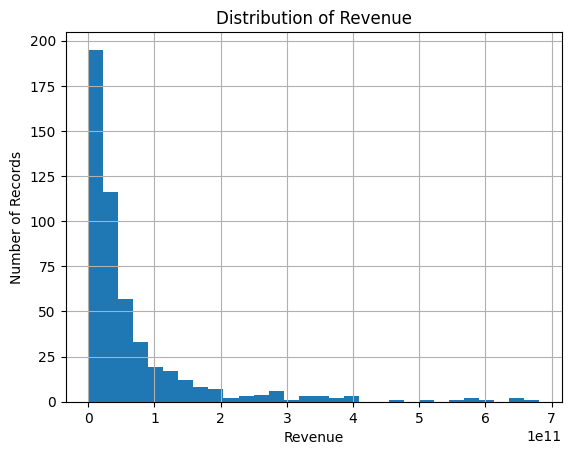

In [54]:
import matplotlib.pyplot as plt

income_clean["Revenue"].hist(bins=30)

plt.xlabel("Revenue")
plt.ylabel("Number of Records")
plt.title("Distribution of Revenue")
plt.show()

### Revenue Distribution on a Log Scale

The Revenue distribution is strongly right-skewed because the selected companies vary considerably in size. A logarithmic scale is used to make the distribution across smaller and larger companies easier to observe.

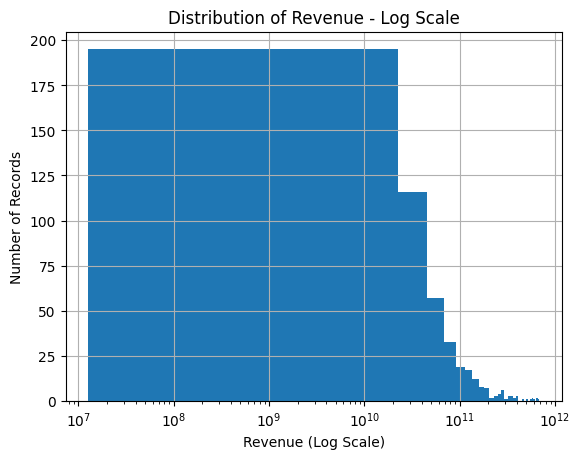

In [56]:
income_clean["Revenue"].hist(bins=30)

plt.xscale("log")
plt.xlabel("Revenue (Log Scale)")
plt.ylabel("Number of Records")
plt.title("Distribution of Revenue - Log Scale")
plt.show()

### Distribution of Net Income

A boxplot is used to examine the spread of Net Income and identify possible extreme values across the selected companies and fiscal years.

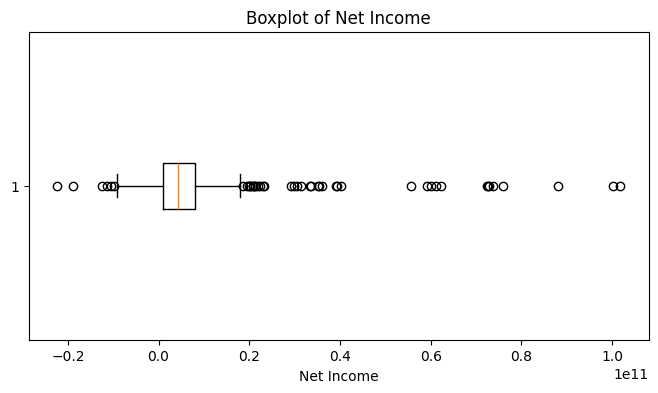

In [57]:
plt.figure(figsize=(8, 4))

plt.boxplot(income_clean["Net Income"].dropna(), vert=False)

plt.xlabel("Net Income")
plt.title("Boxplot of Net Income")
plt.show()

**Observation:** The Net Income distribution contains several extreme values on both the positive and negative sides. This reflects the large differences in profitability and company size across the selected companies.

### Revenue Trend for an Example Company

The following plot shows how Revenue changed over the five-year period for one of the selected companies.

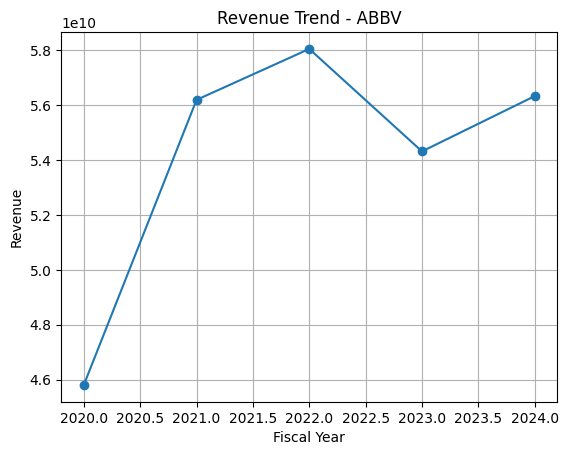

In [58]:
example_ticker = income_clean["Ticker"].iloc[0]

company_income = income_clean[
    income_clean["Ticker"] == example_ticker
].sort_values("Fiscal Year")

plt.plot(
    company_income["Fiscal Year"],
    company_income["Revenue"],
    marker="o"
)

plt.xlabel("Fiscal Year")
plt.ylabel("Revenue")
plt.title(f"Revenue Trend - {example_ticker}")
plt.grid(True)
plt.show()

**Observation:** ABBV's Revenue increased from 2020 to 2022, declined in 2023, and increased again in 2024. This demonstrates how the financial performance of an individual company can change across the five-year period.

### Revenue vs Net Income

The scatter plot below examines the relationship between Revenue and Net Income across the selected companies and fiscal years.

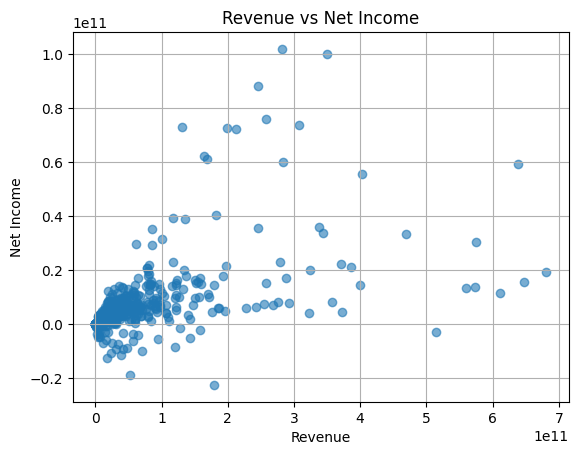

In [59]:
plt.scatter(
    income_clean["Revenue"],
    income_clean["Net Income"],
    alpha=0.6
)

plt.xlabel("Revenue")
plt.ylabel("Net Income")
plt.title("Revenue vs Net Income")
plt.grid(True)
plt.show()

**Observation:** The scatter plot shows a general positive relationship between Revenue and Net Income. However, the wide spread of values indicates that higher Revenue does not always result in proportionally higher Net Income, and some companies report losses despite generating substantial Revenue.

### Save the Cleaned Income Statement

The final cleaned Income Statement dataset is saved as a CSV file in the project outputs folder for use in the subsequent stages of the project.

In [ ]:
output_path = "/content/drive/MyDrive/Data Handling and Machine Learning/week_03/outputs"

income_output_file = os.path.join(output_path, "income_statement.csv")

income_clean.to_csv(income_output_file, index=False)

print("Saved successfully:", income_output_file)

Saved successfully: /content/drive/MyDrive/Data Handling and Machine Learning/week_03/outputs/income_statement.csv


# 4. Filter the Cash Flow Dataset to the Selected Companies

The raw Cash Flow dataset contains records for many companies. Since the project focuses on the selected 100 companies, the dataset is filtered using the SimFinId values from the selected company list.

In [ ]:
df_cashflow_filtered = df_cashflow[df_cashflow["SimFinId"].isin(selected_comp["SimFinId"])
].copy()

print("Raw Cash Flow shape:", df_cashflow.shape)
print("Filtered Cash Flow shape:", df_cashflow_filtered.shape)

print("\nNumber of unique companies:", df_cashflow_filtered["SimFinId"].nunique())

Raw Cash Flow shape: (16842, 28)
Filtered Cash Flow shape: (500, 28)

Number of unique companies: 100


### Verify Financial Records per Company

The number of annual Cash Flow records for each selected company is checked to confirm that all 100 companies have the expected five years of financial data.

In [ ]:
cashflow_records_per_company = df_cashflow_filtered.groupby("Ticker").size()

print("Number of records per company:")
print(cashflow_records_per_company.value_counts())

print("\nMinimum records:", cashflow_records_per_company.min())
print("Maximum records:", cashflow_records_per_company.max())

Number of records per company:
5    100
Name: count, dtype: int64

Minimum records: 5
Maximum records: 5


### Duplicate Records

Duplicate records are checked after filtering to ensure that each company has only one Cash Flow record for each fiscal year.

In [ ]:
print("Exact duplicate rows:", df_cashflow_filtered.duplicated().sum())

company_year_duplicates = df_cashflow_filtered.duplicated(
    subset=["SimFinId", "Fiscal Year"],
    keep=False
)

print("Duplicate company-year records:",
      company_year_duplicates.sum())

Exact duplicate rows: 0
Duplicate company-year records: 0


### Missing Values After Filtering

Missing values are evaluated after filtering to the selected 100 companies. This helps identify data-quality issues in the Cash Flow variables relevant to the project.

In [ ]:
print("Missing Values in Filtered Cash Flow:")

missing_cashflow = df_cashflow_filtered.isnull().sum()

print(missing_cashflow[missing_cashflow > 0])

Missing Values in Filtered Cash Flow:
Net Income/Starting Line                       5
Depreciation & Amortization                    9
Change in Working Capital                      5
Change in Accounts Receivable                482
Change in Inventories                        489
Change in Accounts Payable                   486
Change in Other                              478
Change in Fixed Assets & Intangibles          18
Net Change in Long Term Investment           177
Net Cash from Acquisitions & Divestitures    176
Dividends Paid                               123
Cash from (Repayment of) Debt                 64
Cash from (Repurchase of) Equity              63
Net Cash from Financing Activities             8
dtype: int64


# 5. Clean the Cash Flow Dataset

After filtering the dataset to the selected 100 companies, only the variables required for the project are retained. Company identifiers and reporting information are also kept to ensure that each financial record can be correctly identified.

In [ ]:
cashflow_clean = df_cashflow_filtered[
    [
        "Ticker",
        "SimFinId",
        "Currency",
        "Fiscal Year",
        "Fiscal Period",
        "Report Date",
        "Net Cash from Operating Activities",
        "Change in Fixed Assets & Intangibles"
    ]
].copy()

print("Cleaned Cash Flow shape:", cashflow_clean.shape)

print("\nColumns:")
print(cashflow_clean.columns.tolist())

display(cashflow_clean.head())

Cleaned Cash Flow shape: (500, 8)

Columns:
['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Net Cash from Operating Activities', 'Change in Fixed Assets & Intangibles']


,Ticker,SimFinId,Currency,Fiscal Year,Fiscal Period,Report Date,Net Cash from Operating Activities,Change in Fixed Assets & Intangibles
68,ABBV,61199,USD,2020,FY,2020-12-31,1.758800e+10,-798000000.0
69,ABBV,61199,USD,2021,FY,2021-12-31,2.277700e+10,-787000000.0
70,ABBV,61199,USD,2022,FY,2022-12-31,2.494300e+10,-695000000.0
71,ABBV,61199,USD,2023,FY,2023-12-31,2.283900e+10,-777000000.0
72,ABBV,61199,USD,2024,FY,2024-12-31,1.880600e+10,-974000000.0


### Standardize Cash Flow Variables

The relevant SimFin Cash Flow variables are renamed to match the terminology used in the project. Net Cash from Operating Activities represents Operating Cash Flow, while Change in Fixed Assets & Intangibles is used as the Capital Expenditure measure.

In [ ]:
cashflow_clean = cashflow_clean.rename(columns={
    "Net Cash from Operating Activities": "Operating Cash Flow",
    "Change in Fixed Assets & Intangibles": "Capital Expenditure"
})

print("Columns:")
print(cashflow_clean.columns.tolist())

Columns:
['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Operating Cash Flow', 'Capital Expenditure']


### Calculate Free Cash Flow

Free Cash Flow is calculated using Operating Cash Flow and Capital Expenditure. In the SimFin source data, capital expenditure is represented as a negative cash outflow, so it is added to Operating Cash Flow when calculating Free Cash Flow.

In [ ]:
cashflow_clean["Free Cash Flow"] = (
    cashflow_clean["Operating Cash Flow"]
    + cashflow_clean["Capital Expenditure"]
)

print("Columns:")
print(cashflow_clean.columns.tolist())

display(
    cashflow_clean[
        ["Ticker", "Fiscal Year", "Operating Cash Flow",
         "Capital Expenditure", "Free Cash Flow"]
    ].head()
)

Columns:
['Ticker', 'SimFinId', 'Currency', 'Fiscal Year', 'Fiscal Period', 'Report Date', 'Operating Cash Flow', 'Capital Expenditure', 'Free Cash Flow']


,Ticker,Fiscal Year,Operating Cash Flow,Capital Expenditure,Free Cash Flow
68,ABBV,2020,1.758800e+10,-798000000.0,1.679000e+10
69,ABBV,2021,2.277700e+10,-787000000.0,2.199000e+10
70,ABBV,2022,2.494300e+10,-695000000.0,2.424800e+10
71,ABBV,2023,2.283900e+10,-777000000.0,2.206200e+10
72,ABBV,2024,1.880600e+10,-974000000.0,1.783200e+10


### Handling Missing Cash Flow Values

Capital Expenditure contains 18 missing values in the filtered dataset. Since Free Cash Flow is calculated using Operating Cash Flow and Capital Expenditure, Free Cash Flow is also unavailable for these records.

These records are retained to preserve the complete five-year history for all selected companies. The missing values are left as NaN rather than using statistical imputation, which could introduce artificial financial values.

In [ ]:
print("Missing values in the cleaned Cash Flow dataset:")
print(cashflow_clean.isnull().sum())

Missing values in the cleaned Cash Flow dataset:
Ticker                  0
SimFinId                0
Currency                0
Fiscal Year             0
Fiscal Period           0
Report Date             0
Operating Cash Flow     0
Capital Expenditure    18
Free Cash Flow         18
dtype: int64


### Convert Report Date

The report date is converted from text to a datetime format to ensure that dates can be correctly sorted, filtered, and analyzed in later stages of the project.

In [ ]:
cashflow_clean["Report Date"] = pd.to_datetime(
    cashflow_clean["Report Date"],
    errors="coerce"
)

print("Report date data type:", cashflow_clean["Report Date"].dtype)
print("Missing report dates:", cashflow_clean["Report Date"].isnull().sum())

Report date data type: datetime64[ns]
Missing report dates: 0


### Final Validation

The cleaned Cash Flow dataset is validated to confirm that it contains the expected number of companies and records, has no duplicate company-year entries, and retains the required five-year financial history.

In [ ]:
print("Final Cash Flow shape:", cashflow_clean.shape)

print("Unique companies:", cashflow_clean["Ticker"].nunique())

print(
    "Duplicate company-year records:",
    cashflow_clean.duplicated(
        subset=["SimFinId", "Fiscal Year"]
    ).sum()
)

records_per_company = cashflow_clean.groupby("Ticker").size()

print("\nRecords per company:")
print(records_per_company.value_counts())

print("\nRemaining missing values:")
print(cashflow_clean.isnull().sum())

Final Cash Flow shape: (500, 9)
Unique companies: 100
Duplicate company-year records: 0

Records per company:
5    100
Name: count, dtype: int64

Remaining missing values:
Ticker                  0
SimFinId                0
Currency                0
Fiscal Year             0
Fiscal Period           0
Report Date             0
Operating Cash Flow     0
Capital Expenditure    18
Free Cash Flow         18
dtype: int64


## EDA - Cash Flow

This section explores the cleaned Cash Flow data of the selected 100 companies over five fiscal years. The analysis focuses on Operating Cash Flow, Capital Expenditure, and Free Cash Flow to examine their distributions, trends, and possible extreme values.

### Distribution of Operating Cash Flow

The histogram below shows the distribution of Operating Cash Flow across the selected companies and fiscal years.

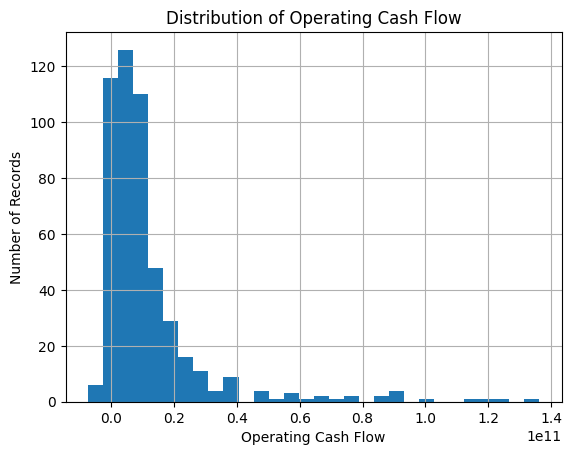

In [60]:
cashflow_clean["Operating Cash Flow"].hist(bins=30)

plt.xlabel("Operating Cash Flow")
plt.ylabel("Number of Records")
plt.title("Distribution of Operating Cash Flow")
plt.show()

### Distribution of Free Cash Flow

A boxplot is used to examine the spread of Free Cash Flow and identify possible extreme values across the selected companies and fiscal years.

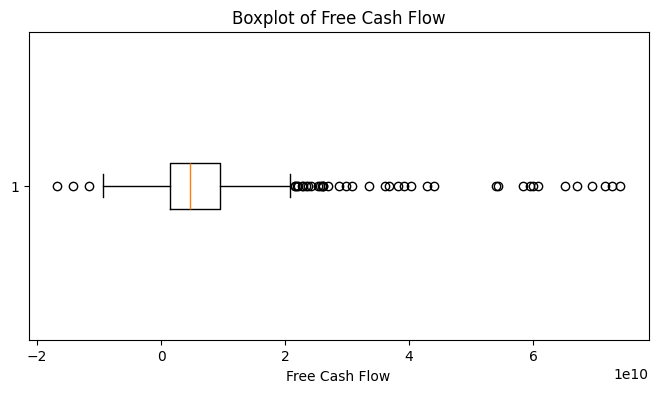

In [61]:
plt.figure(figsize=(8, 4))

plt.boxplot(
    cashflow_clean["Free Cash Flow"].dropna(),
    vert=False
)

plt.xlabel("Free Cash Flow")
plt.title("Boxplot of Free Cash Flow")
plt.show()

**Observation:** Free Cash Flow contains several extreme values, particularly on the positive side. There are also some negative values, showing that certain company-year records had negative Free Cash Flow during the five-year period.

### Operating Cash Flow Trend for an Example Company

The following plot shows how Operating Cash Flow changed over the five-year period for one of the selected companies.

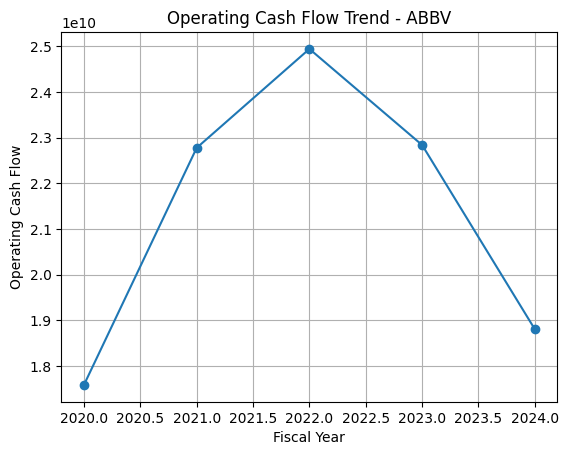

In [62]:
example_ticker = "ABBV"

company_cashflow = cashflow_clean[
    cashflow_clean["Ticker"] == example_ticker
].sort_values("Fiscal Year")

plt.plot(
    company_cashflow["Fiscal Year"],
    company_cashflow["Operating Cash Flow"],
    marker="o"
)

plt.xlabel("Fiscal Year")
plt.ylabel("Operating Cash Flow")
plt.title(f"Operating Cash Flow Trend - {example_ticker}")
plt.grid(True)
plt.show()

**Observation:** ABBV's Operating Cash Flow increased from 2020 to 2022 and then declined during 2023 and 2024. This shows how a company's cash generated from operating activities can vary across the five-year period.

### Operating Cash Flow vs Free Cash Flow

The scatter plot below examines the relationship between Operating Cash Flow and Free Cash Flow across the selected companies and fiscal years.

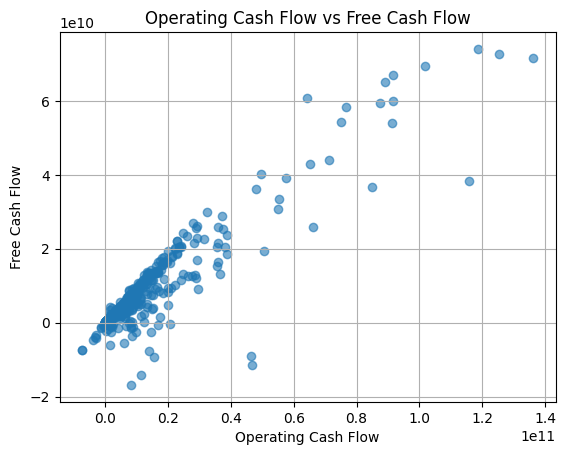

In [63]:
plt.scatter(
    cashflow_clean["Operating Cash Flow"],
    cashflow_clean["Free Cash Flow"],
    alpha=0.6
)

plt.xlabel("Operating Cash Flow")
plt.ylabel("Free Cash Flow")
plt.title("Operating Cash Flow vs Free Cash Flow")
plt.grid(True)
plt.show()

**Observation:** The scatter plot shows a strong positive relationship between Operating Cash Flow and Free Cash Flow. In general, companies with higher Operating Cash Flow also have higher Free Cash Flow, although differences in Capital Expenditure cause some variation between the two measures.

### Save the Cleaned Cash Flow Dataset

The validated Cash Flow dataset is saved as a CSV file in the shared project outputs folder for use in later stages of the project.

In [ ]:
cashflow_output_file = os.path.join(
    output_path,
    "cash_flow.csv"
)

cashflow_clean.to_csv(
    cashflow_output_file,
    index=False
)

print("Saved successfully:", cashflow_output_file)

Saved successfully: /content/drive/MyDrive/Data Handling and Machine Learning/week_03/outputs/cash_flow.csv
